# Importing USGS Earthquake API

The main goal of this file is to collect earthquake data from the USGS Earthquake API.

Required fields:

- Magnitude
- Latitude
- Longitude
- Depth
- Time

Output:

earthquake_data.csv

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"

PARAMS = {

    "format": "geojson",


    "starttime": "2000-01-01",


    "endtime": "2026-12-31",


    "minmagnitude": 3.5,


    # India bounding box

    "minlatitude": 6,


    "maxlatitude": 38,


    "minlongitude": 68,


    "maxlongitude": 98

}

In [2]:
response = requests.get(URL, params=PARAMS, timeout=30)
response.raise_for_status()

print(response.status_code)

200


In [3]:
earthquake_json = response.json()

print(type(earthquake_json))

<class 'dict'>


In [4]:
print(len(earthquake_json["features"]))

18702


In [5]:
records = []

for source_event_id, event in enumerate(earthquake_json["features"]):

    properties = event["properties"]

    geometry = event["geometry"]

    records.append({

        "SourceEventID": source_event_id,

        "USGSEventID": event.get("id"),

        "Magnitude": properties["mag"],

        "Latitude": geometry["coordinates"][1],

        "Longitude": geometry["coordinates"][0],

        "Depth": geometry["coordinates"][2],

        "Time": properties["time"]

    })

In [6]:
earthquake_df = pd.DataFrame(records)

earthquake_df.head()

,SourceEventID,USGSEventID,Magnitude,Latitude,Longitude,Depth,Time
0,0,us7000sztw,4.3,25.5695,90.7428,10.000,1783837839013
1,1,us7000szsn,4.5,16.4995,84.5232,10.000,1783812945479
2,2,us7000szsk,4.2,22.6970,95.8926,10.000,1783809564089
3,3,us7000sz2t,4.2,19.2225,76.8290,10.000,1783541245081
4,4,us6000tavd,4.3,37.3926,72.1298,216.967,1783491294818


In [7]:
earthquake_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18702 entries, 0 to 18701
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SourceEventID  18702 non-null  int64  
 1   USGSEventID    18702 non-null  object 
 2   Magnitude      18702 non-null  float64
 3   Latitude       18702 non-null  float64
 4   Longitude      18702 non-null  float64
 5   Depth          18702 non-null  float64
 6   Time           18702 non-null  int64  
dtypes: float64(4), int64(2), object(1)
memory usage: 1022.9+ KB


In [8]:
earthquake_df.isnull().sum()

SourceEventID    0
USGSEventID      0
Magnitude        0
Latitude         0
Longitude        0
Depth            0
Time             0
dtype: int64

In [9]:
earthquake_df = earthquake_df.dropna()

In [10]:
earthquake_df.describe()

,SourceEventID,Magnitude,Latitude,Longitude,Depth,Time
count,18702.000000,18702.000000,18702.000000,18702.000000,18702.000000,1.870200e+04
mean,9350.500000,4.397573,26.327394,83.360721,61.034851,1.324939e+12
std,5398.946703,0.442511,11.165064,10.450121,65.225190,2.380414e+11
min,0.000000,3.500000,6.000000,68.000400,0.000000,9.467043e+11
25%,4675.250000,4.100000,13.654000,71.408375,10.000000,1.114807e+12
50%,9350.500000,4.400000,30.689000,85.902500,32.000000,1.250152e+12
75%,14025.750000,4.600000,36.345900,93.747000,95.900000,1.533259e+12
max,18701.000000,7.800000,38.000000,97.997400,400.570000,1.783838e+12


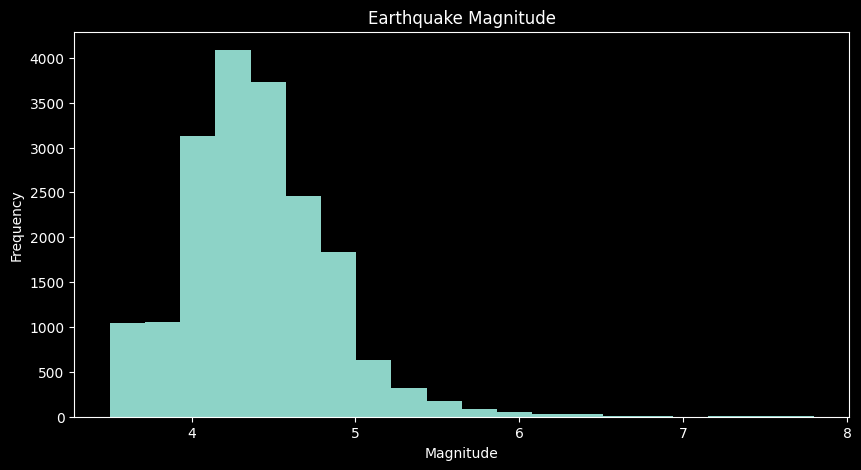

In [11]:
plt.figure(figsize=(10,5))

plt.hist(

    earthquake_df["Magnitude"],

    bins=20

)

plt.title("Earthquake Magnitude")

plt.xlabel("Magnitude")

plt.ylabel("Frequency")

plt.show()

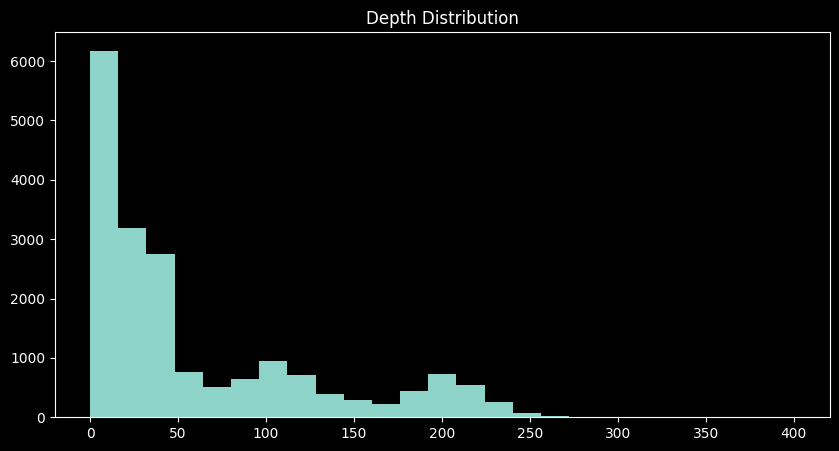

In [12]:
plt.figure(figsize=(10,5))

plt.hist(

    earthquake_df["Depth"],

    bins=25

)

plt.title("Depth Distribution")

plt.show()

In [13]:
earthquake_df.to_csv(

    "../datasets/earthquake_data.csv",

    index=False

)

print("Dataset Saved Successfully")

Dataset Saved Successfully


In [14]:
import os

os.listdir("../datasets")

['combined_disasters.csv',
 'earthquake_data.csv',
 'event_infrastructure_summary.csv',
 'final_disaster_dataset.csv',
 'final_disaster_dataset_engineered.csv',
 'final_disaster_dataset_with_infrastructure.csv',
 'gdacs_data.csv',
 'india-latest.osm.pbf',
 'india_infrastructure.parquet',
 'osm_checkpoints',
 'osm_regions',
 'population_clean.npy',
 'population_data.tif',
 'population_metadata.json',
 'population_selected_metadata.json',
 'shapefiles',
 'useful_disaster_events.csv',
 'weather_data.csv',
 'weather_useful_events.csv']